In [1]:
%matplotlib inline

import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
import triton

import cute_vector_add
import triton_vector_add
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

N = 1 << 20

In [6]:
AUTOTUNE = True  # False runs each kernel with its own defaults

TRITON_KERNEL = triton_vector_add.vector_add_kernel(autotune=AUTOTUNE)

IMPLEMENTATIONS = {
    "torch": make_runner("torch", torch.add),
    "torch_compile": make_runner("torch_compile", lambda x, y: x + y),
    "triton": make_runner(
        "triton",
        TRITON_KERNEL,
        extra_args=lambda a, b, out: (a.numel(),),
        grid=lambda meta: (triton.cdiv(meta["n"], meta["BLOCK_SIZE"]),),
    ),
    "cute": make_runner("cute", cute_vector_add.add(autotune=False)),
    "cuda": make_runner("cuda", "cuda_vector_add.cu", entry="add"),
}

In [3]:
# Tests: sizes around the block boundary catch kernels that drop the tail.
for n in [1, 255, 256, 257, 1000, N]:
    inputs = make_inputs((n,), (n,))
    for name, fn in IMPLEMENTATIONS.items():
        torch.testing.assert_close(fn(*inputs), torch.add(*inputs), msg=f"{name}, n={n}")
print("OK")

/home/fvelikon/projects/ysda-dsl-benches/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


OK


         torch: 12.624 us (p20-p80: 12.256-13.024) | 0.083062 TFLOP/s | 996.75 GB/s | 1.47x
 torch_compile: 18.512 us (p20-p80: 16.109-24.320) | 0.056643 TFLOP/s | 679.72 GB/s | 1.00x
        triton: 12.288 us (p20-p80: 11.386-15.053) | 0.085333 TFLOP/s | 1024.00 GB/s | 1.51x
          cute: 26.800 us (p20-p80: 24.678-34.630) | 0.039126 TFLOP/s | 469.51 GB/s | 0.69x
          cuda: 14.304 us (p20-p80: 13.190-14.502) | 0.073306 TFLOP/s | 879.68 GB/s | 1.29x


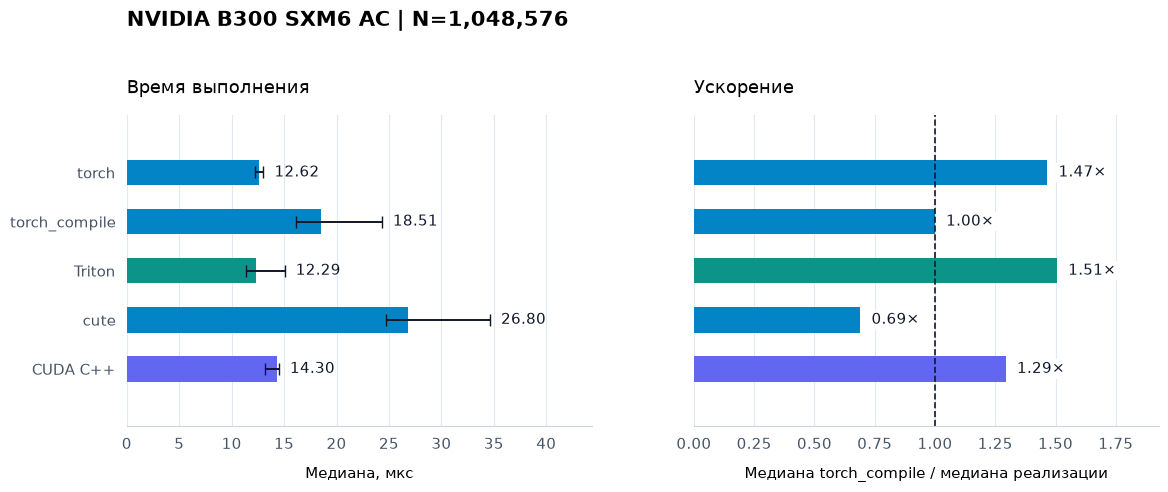

triton config: BLOCK_SIZE: 1024, num_warps: 4, num_ctas: 1, num_stages: 3, maxnreg: None
cute config: {}


In [7]:
inputs = make_inputs((N,), (N,))
results = run_benchmark(IMPLEMENTATIONS, inputs, reference=torch.add, flops=N)
plot_benchmark(results, baseline="torch_compile", title=f"{torch.cuda.get_device_name()} | N={N:,}")
plt.show()
if AUTOTUNE:
    print("triton config:", TRITON_KERNEL.best_config)
    print("cute config:", IMPLEMENTATIONS["cute"].asm()["add"]["config"])

In [8]:
for name, fn in IMPLEMENTATIONS.items():
    dump_asm(fn.asm(), Path("asm") / name)
    print(name, list(fn.asm()))

torch []


torch_compile []
triton ['vector_add_kernel']
cute ['add']
cuda ['cuda_vector_add']
